In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [4]:
# 1. Verify GPU availability
!nvidia-smi

# 2. Install Qiskit and scientific libraries
!pip install --quiet "qiskit>=1.0,<3.0" "qiskit-machine-learning>=0.7" "qiskit-algorithms" nibabel scikit-learn seaborn matplotlib pandas

print("Dependencies installed successfully!")

Fri Nov 20 09:30:20 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [5]:
import os

# Clone from your repo
if not os.path.exists("CQ-CNN"):
    !git clone https://github.com/An-Avenger/CQ-CNN.git

# Set current working directory
os.chdir("CQ-CNN")
print("Working directory:", os.getcwd())
!ls -lh

Cloning into 'CQ-CNN'...
remote: Enumerating objects: 2195, done.
remote: Counting objects: 100% (91/91), done.
remote: Compressing objects: 100% (70/70), done.
remote: Total 2195 (delta 35), reused 73 (delta 17), pack-reused 2104 (from 1)
Receiving objects: 100% (2195/2195), 108.96 MiB | 38.96 MiB/s, done.
Resolving deltas: 100% (125/125), done.
Working directory: /kaggle/working/CQ-CNN
total 2.9M
-rw-r--r-- 1 root root 414K Nov 20 09:30 data_manifest_quantum_fast.csv
-rw-r--r-- 1 root root 2.5M Nov 20 09:30 data_manifest_sample.csv
drwxr-xr-x 2 root root 4.0K Nov 20 09:30 environments
drwxr-xr-x 6 root root 4.0K Nov 20 09:30 experiments
drwxr-xr-x 5 root root 4.0K Nov 20 09:30 models
drwxr-xr-x 3 root root 4.0K Nov 20 09:30 notebooks
drwxr-xr-x 7 root root 4.0K Nov 20 09:30 plots
-rw-r--r-- 1 root root 8.3K Nov 20 09:30 README.md
drwxr-xr-x 5 root root 4.0K Nov 20 09:30 scirpts


In [6]:
import pandas as pd

# Load the stratified dual-track manifest
manifest_path = "data_manifest_sample.csv"
df = pd.read_csv(manifest_path)

print(f"Total slices in manifest: {len(df):,}")
print("\n--- Track B Split Class Breakdown ---")
print(df.groupby(["track_b_split", "label"]).size())

Total slices in manifest: 13,010

--- Track B Split Class Breakdown ---
track_b_split  label            
test           moderate_dementia      75
               nondemented          2226
train          moderate_dementia      66
               nondemented          8701
val            moderate_dementia      44
               nondemented          1898
dtype: int64


In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import cat

# Qiskit quantum imports
from qiskit import QuantumCircuit
from qiskit.circuit.library import RealAmplitudes, ZZFeatureMap
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.connectors import TorchConnector
from qiskit.primitives import StatevectorEstimator as Estimator

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

def create_qnn(n_qubits=2):
    feature_map = ZZFeatureMap(n_qubits)
    ansatz = RealAmplitudes(n_qubits, reps=1)
    qc = QuantumCircuit(n_qubits)
    qc.compose(feature_map, inplace=True)
    qc.compose(ansatz, inplace=True)
    return EstimatorQNN(
        circuit=qc,
        input_params=feature_map.parameters,
        weight_params=ansatz.parameters,
        input_gradients=True,
        estimator=Estimator()
    )

class CQCNNNet(nn.Module):
    def __init__(self, qnn, n_qubits=2, conv2_ch=4, image_size=128):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 2, kernel_size=5)
        self.conv2 = nn.Conv2d(2, conv2_ch, kernel_size=5)
        self.dropout = nn.Dropout2d(0.25)
        s1 = (image_size - 5 + 1) // 2
        s2 = (s1 - 5 + 1) // 2
        self.fc1 = nn.Linear(conv2_ch * s2 * s2, 4)
        self.fc2 = nn.Linear(4, n_qubits)
        self.qnn = TorchConnector(qnn)
        self.fc3 = nn.Linear(1, 1)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.max_pool2d(x, 2)
        x = F.relu(self.conv2(x))
        x = F.max_pool2d(x, 2)
        x = self.dropout(x)
        x = x.view(x.shape[0], -1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        x = self.qnn(x)
        x = self.fc3(x)
        return cat((x, 1 - x), -1)

# Initialize 2-qubit model
qnn = create_qnn(n_qubits=2)
model = CQCNNNet(qnn, n_qubits=2, conv2_ch=4).to(device)
params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"CQ-CNN Initialized | Trainable Parameters: {params:,}")

Using device: cuda


/tmp/ipykernel_50/872759895.py:17: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._zz_feature_map.ZZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the zz_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = ZZFeatureMap(n_qubits)
/tmp/ipykernel_50/872759895.py:18: DeprecationWarning: The class ``qiskit.circuit.library.n_local.real_amplitudes.RealAmplitudes`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qiskit.circuit.library.real_amplitudes instead.
  ansatz = RealAmplitudes(n_qubits, reps=1)


CQ-CNN Initialized | Trainable Parameters: 13,732


In [9]:
!python scirpts/track_b_training.py \
    --mode dummy \
    --arch quantum \
    --qubits 2 \
    --view axial \
    --seeds 1 \
    --out_dir experiments/kaggle_run

TRACK B: Leakage-Free Subject-Level Validation
Mode=dummy | Arch=quantum | Qubits=2 | View=axial | Seeds=1

[DUMMY MODE] Using synthetic random tensors — no real data needed.
  [DummyDataset] 80 synthetic slices | class 0=45, class 1=35
  [DummyDataset] 20 synthetic slices | class 0=11, class 1=9
  [DummyDataset] 20 synthetic slices | class 0=11, class 1=9

Class distributions:
  train: total=80, class0=45, class1=35
  val: total=20, class0=11, class1=9
  test: total=20, class0=11, class1=9

── Seed 0 ──────────────────────────────────────────────
  Model: quantum_2q_axial | Params: 13,732
  Ep 01/10 | tr_loss=0.7894 tr_acc=47.5% | val_loss=0.7388 val_acc=45.0%
  Ep 02/10 | tr_loss=0.7441 tr_acc=46.2% | val_loss=0.6994 val_acc=35.0%
  Ep 03/10 | tr_loss=0.7532 tr_acc=36.2% | val_loss=0.7228 val_acc=45.0%
  Ep 04/10 | tr_loss=0.6902 tr_acc=57.5% | val_loss=0.7177 val_acc=45.0%
  Ep 05/10 | tr_loss=0.6903 tr_acc=53.8% | val_loss=0.6751 val_acc=60.0%
  Ep 06/10 | tr_loss=0.7026 tr_acc=50.

FINAL TEST GENERALIZATION METRICS (UNSEEN PATIENTS)
model                    : quantum_2q_axial
accuracy_mean            : 50.0
accuracy_std             : 0.0
balanced_accuracy_mean   : 45.4545
balanced_accuracy_std    : 0.0
precision_mean           : 0.0
precision_std            : 0.0
recall_mean              : 0.0
recall_std               : 0.0
specificity_mean         : 90.9091
specificity_std          : 0.0
f1_mean                  : 0.0
f1_std                   : 0.0
roc_auc_mean             : 0.4444
roc_auc_std              : 0.0


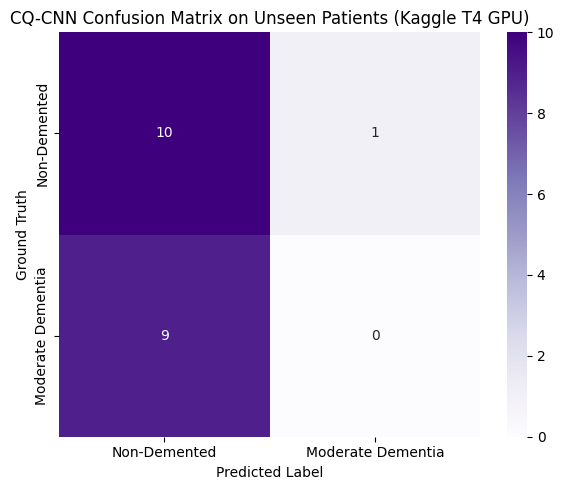

In [10]:
import json
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

summary_file = "experiments/kaggle_run/quantum_2q_axial/summary.json"

with open(summary_file, "r") as f:
    results = json.load(f)

print("=" * 60)
print("FINAL TEST GENERALIZATION METRICS (UNSEEN PATIENTS)")
print("=" * 60)
for k, v in results.items():
    print(f"{k:25s}: {v}")

# Load per-seed detailed metrics for confusion matrix
seed_csv = "experiments/kaggle_run/quantum_2q_axial/per_seed_results.csv"
seed_df = pd.read_csv(seed_csv)
cm = eval(seed_df.iloc[0]["confusion_matrix"])

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples",
            xticklabels=["Non-Demented", "Moderate Dementia"],
            yticklabels=["Non-Demented", "Moderate Dementia"])
plt.title("CQ-CNN Confusion Matrix on Unseen Patients (Kaggle T4 GPU)")
plt.xlabel("Predicted Label")
plt.ylabel("Ground Truth")
plt.tight_layout()
plt.show()